In [41]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from openpiv import windef

DATA_DIR = Path.cwd() / "sim_000000"

print("Dataset folder exists:", DATA_DIR.exists())

for filename in ["density_000106.npz", "density_000107.npz"]:
    path = DATA_DIR / filename
    print(filename, ":", path.exists())

Dataset folder exists: True
density_000106.npz : True
density_000107.npz : True


In [42]:
# Create folder for density images
IMAGE_DIR = Path.cwd() / "density_images"
IMAGE_DIR.mkdir(exist_ok=True)

# Use the same slicing convention as your partner
Z_INDEX = 50

for number in [106, 107]:

    # Load ScalarFlow density data
    file_path = DATA_DIR / f"density_{number:06d}.npz"

    with np.load(file_path) as data:
        density = data["data"]

    # Extract 2D density slice
    image = density[:, :, Z_INDEX, 0].T

    # Save as grayscale PNG
    output_path = IMAGE_DIR / f"density_{number:06d}_Z{Z_INDEX}.png"

    plt.imsave(output_path, image, cmap="gray")

    print("Saved:", output_path)

Saved: /Users/Aravind/MQP/Algorithm implementation/density_images/density_000106_Z50.png
Saved: /Users/Aravind/MQP/Algorithm implementation/density_images/density_000107_Z50.png


Frame A shape: (178, 100)
Frame B shape: (178, 100)


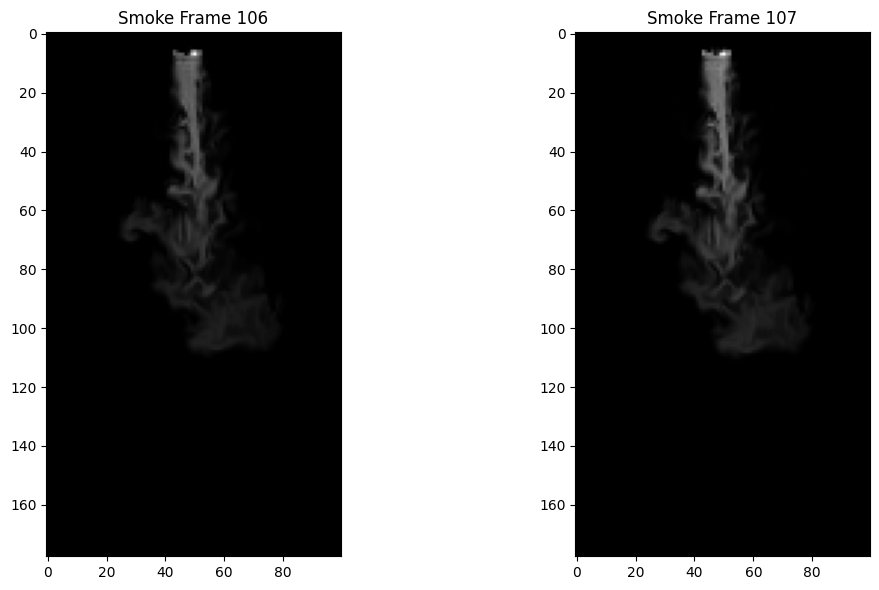

In [43]:
# Load the two density images
frame_a = tools.imread(
    str(IMAGE_DIR / "density_000106_Z50.png")
)

frame_b = tools.imread(
    str(IMAGE_DIR / "density_000107_Z50.png")
)

# Check dimensions
print("Frame A shape:", frame_a.shape)
print("Frame B shape:", frame_b.shape)

# Display both images
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(frame_a, cmap="gray")
axes[0].set_title("Smoke Frame 106")

axes[1].imshow(frame_b, cmap="gray")
axes[1].set_title("Smoke Frame 107")

plt.tight_layout()
plt.show()

In [44]:
# Configure multi-pass PIV
settings = windef.PIVSettings()

# Three passes with progressively smaller windows
settings.windowsizes = (32, 16, 8)
settings.overlap = (16, 8, 4)
settings.num_iterations = 3

# Algorithm settings
settings.correlation_method = "circular"
settings.deformation_method = "symmetric"
settings.subpixel_method = "gaussian"

# Run multi-pass PIV
x, y, u, v, flags = windef.simple_multipass(
    frame_a,
    frame_b,
    settings
)

print("Multi-pass PIV completed successfully!")
print("Velocity field shape:", u.shape)
print("Total vectors:", u.size)

Multi-pass PIV completed successfully!
Velocity field shape: (43, 24)
Total vectors: 1032


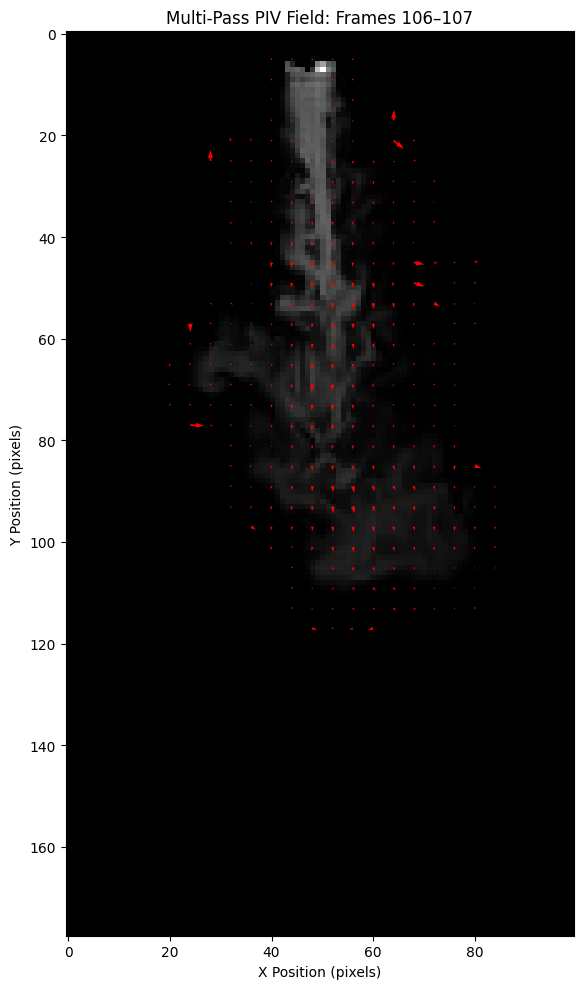

In [45]:
# Keep valid PIV vectors
valid = (
    ~np.asarray(flags, dtype=bool)
    & np.isfinite(u)
    & np.isfinite(v)
)

# Convert OpenPIV coordinates to image coordinates
plot_y = frame_a.shape[0] - 1 - y

# Plot smoke image
plt.figure(figsize=(8, 10))
plt.imshow(frame_a, cmap="gray", origin="upper")

# Plot PIV displacement vectors
plt.quiver(
    x[valid],
    plot_y[valid],
    u[valid],
    -v[valid],
    color="red",
    angles="xy",
    scale_units="xy",
    scale=1
)

plt.title("Multi-Pass PIV Field: Frames 106–107")
plt.xlabel("X Position (pixels)")
plt.ylabel("Y Position (pixels)")

plt.tight_layout()
plt.show()

In [47]:
# Generate density images for frames 112 and 113
for number in [112, 113]:

    file_path = DATA_DIR / f"density_{number:06d}.npz"

    with np.load(file_path) as data:
        density = data["data"]

    # Same slicing convention as before
    image = density[:, :, 50, 0].T

    # Save image
    output_path = IMAGE_DIR / f"density_{number:06d}_Z50.png"

    plt.imsave(output_path, image, cmap="gray")

    print("Saved:", output_path)

Saved: /Users/Aravind/MQP/Algorithm implementation/density_images/density_000112_Z50.png
Saved: /Users/Aravind/MQP/Algorithm implementation/density_images/density_000113_Z50.png


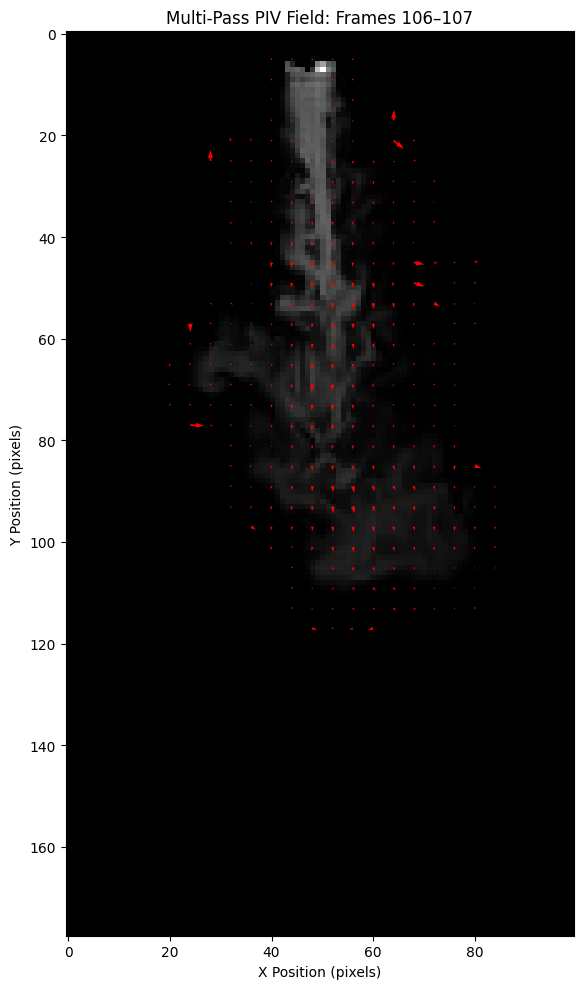

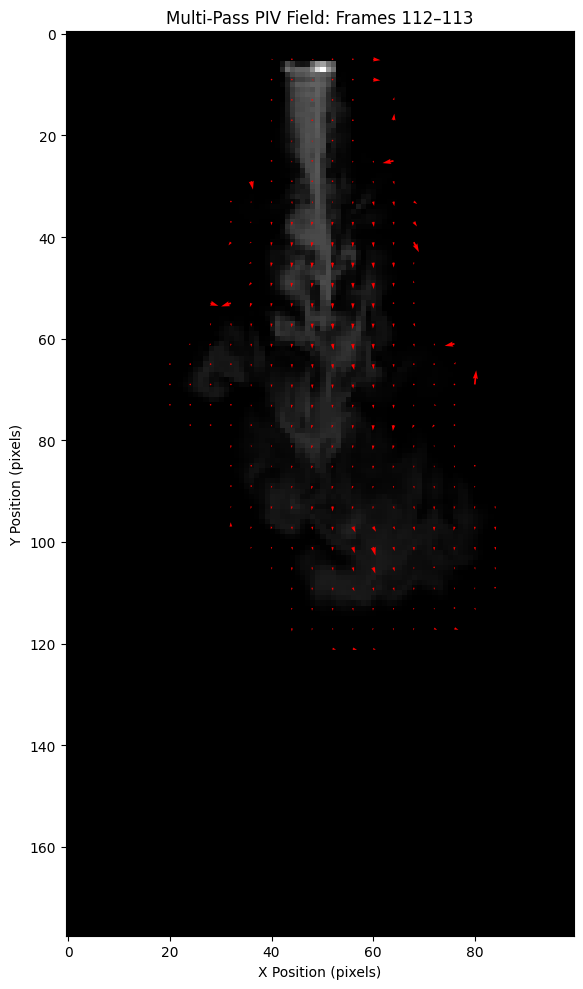

In [48]:
import numpy as np
import matplotlib.pyplot as plt


# Choose consecutive frame pairs
frame_pairs = [
    (106, 107),
    (112, 113)
]

for start, end in frame_pairs:

    # Load density-slice images
    frame_a = tools.imread(
        str(IMAGE_DIR / f"density_{start:06d}_Z50.png")
    )

    frame_b = tools.imread(
        str(IMAGE_DIR / f"density_{end:06d}_Z50.png")
    )

    # Run multi-pass PIV
    x, y, u, v, flags = windef.simple_multipass(
        frame_a,
        frame_b,
        settings
    )

    # Keep valid vectors
    valid = (
        ~np.asarray(flags, dtype=bool)
        & np.isfinite(u)
        & np.isfinite(v)
    )

    # Convert to image coordinates
    plot_y = frame_a.shape[0] - 1 - y

    # Plot the resulting vector field
    plt.figure(figsize=(8, 10))
    plt.imshow(frame_a, cmap="gray", origin="upper")

    plt.quiver(
        x[valid],
        plot_y[valid],
        u[valid],
        -v[valid],
        color="red",
        angles="xy",
        scale_units="xy",
        scale=1
    )

    plt.title(f"Multi-Pass PIV Field: Frames {start}–{end}")
    plt.xlabel("X Position (pixels)")
    plt.ylabel("Y Position (pixels)")

    plt.tight_layout()
    plt.show()